# Sampling Methods
In this seminar we will practice some of the concepts discussed in L04

## Collision detection

Collision detection is the computational problem of detecting an intersection of two or more objects in virtual space. Collision detection is a classic problem of computational geometry with applications in computer graphics, physical simulation, robotics and etc.

There are multiple ways to represent objects: Polygons, Polyhedral, Algebraic models, 3D triangles, meshes, NURBS, bitmaps,  SDFs, etc.

For each of the object representations, there is an exact collision checker, however it might be tremendously complex and calculating the full Cobswould be impractical. This is just a brief introduction to the topic.

<img src="https://i.sstatic.net/HGFVf.png" alt="Alternative text" />
<img src="https://i.sstatic.net/tEd5E.png" alt="Alternative text" />


Regardless of the method, we can follow a 2-phase strategy:
* Broad Phase: to avoid expensive calculations, we broadly describe objects **as boxes or spheres**.
* Narrow Phase: details are checked. For some configurations (close to obstacles) this can be the only way.

<img src="https://happycoding.io/tutorials/processing/images/collision-detection-6.png" alt="Alternative text" />

**Remark**: this seminar will describe examples of checking collision in continous space

Our first task is to play around with visualisation here, below is provided some code for this.


## Imagine that we have point and obstacle in front of it

In [1]:
%matplotlib inline
from matplotlib import pyplot as plt
import numpy as np

def render(point,obstacle):
    plt.plot(point[0],point[1], marker='o',color=[1,0,0])
    plt.gca().add_patch(plt.Circle((obstacle[0], obstacle[1]), obstacle[2], fill=True))
    plt.axis('equal')
    plt.show()

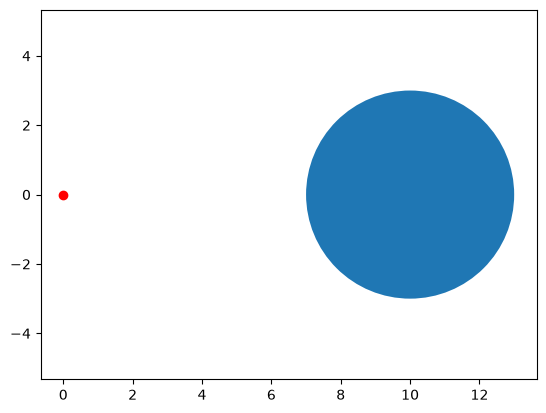

In [2]:
point = np.array([0,0]) # x,y
obstacle = [10,0,3] #  x,y,radius (assume that is circle)

render(point,obstacle)

# Task 1: check collision point with circle
* subtask A - realise check collision
* subtask B - think how to avoid collision with that knowledge

In [3]:
def check_collision(point, obstacle):
    center = np.array(obstacle[:2])
    radius = obstacle[2]
    return np.linalg.norm(point - center) <= radius


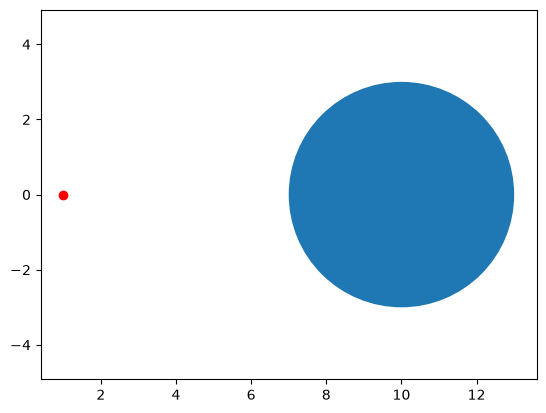

collision detected:  False


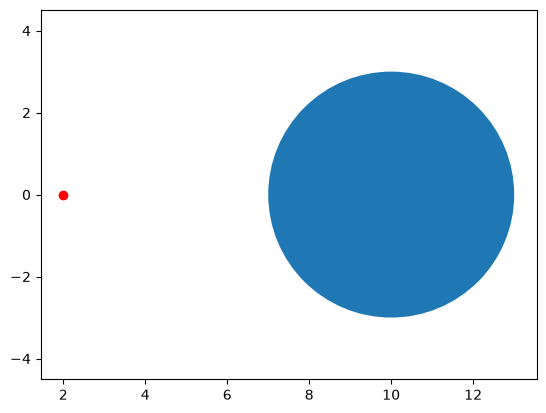

collision detected:  False


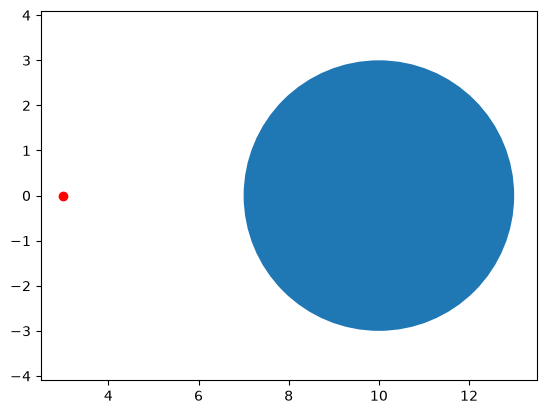

collision detected:  False


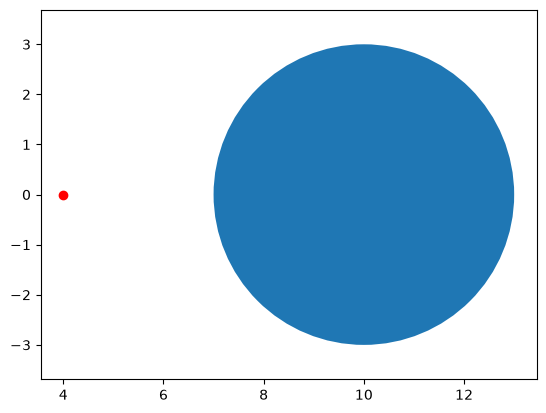

collision detected:  False


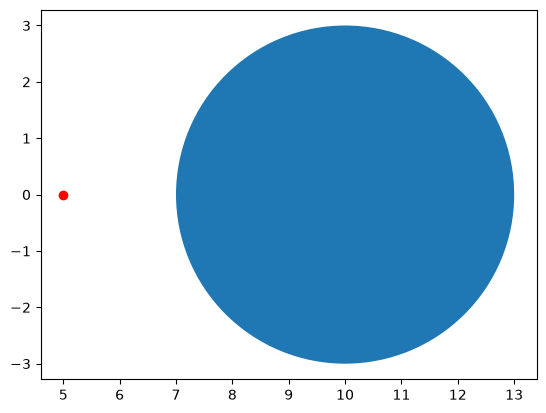

collision detected:  False


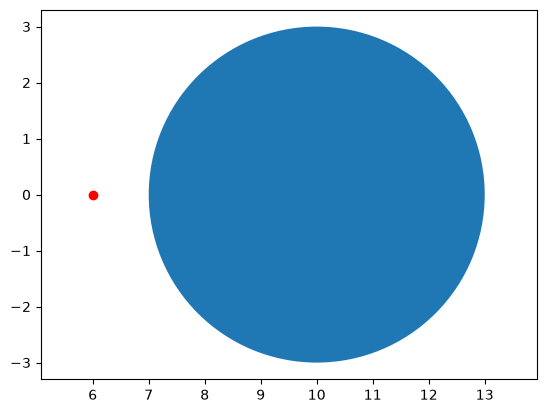

collision detected:  False


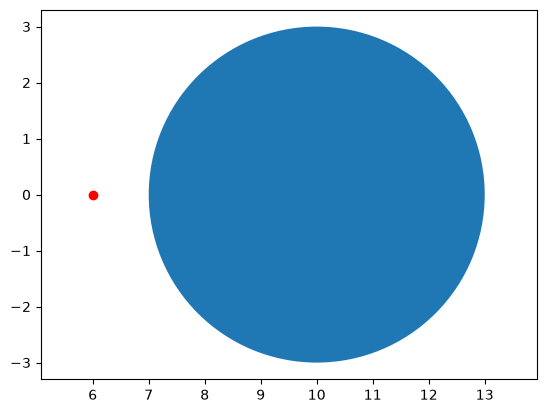

collision detected:  False


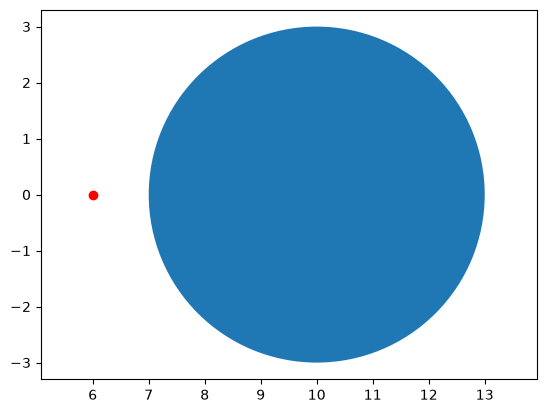

collision detected:  False


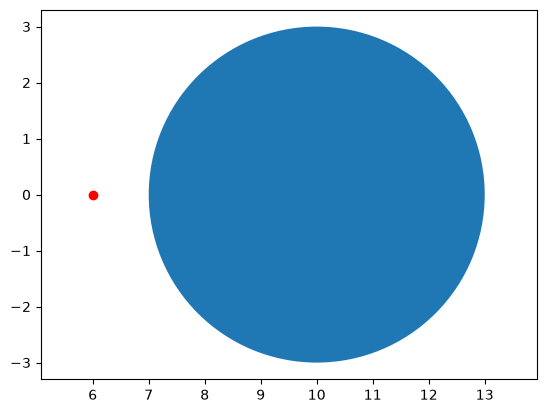

collision detected:  False


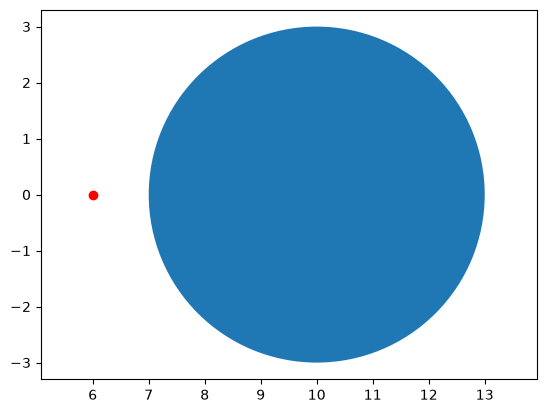

collision detected:  False


In [4]:
point = np.array([0, 0]) # x, y
obstacle = [10, 0, 3] # x, y, radius
velocity = np.array([1, 0]) # vx, vy
for _ in range(10):
    next_point = point + velocity
    if check_collision(next_point, obstacle):
        velocity = np.zeros(2) # Stop before entering the obstacle.
    else:
        point = next_point
    collision = check_collision(point, obstacle)
    render(point, obstacle)
    print("collision detected: ", collision)


# Task 2: check collision 2R manipulator with circle
* subtask A - realise check collision for 
* subtask B - think how to avoid collision with that knowledge

<img src="https://www.researchgate.net/profile/Nilanjan-Chakraborty-7/publication/224090716/figure/fig2/AS:669088540008473@1536534547577/A-planar-manipulator-with-2-revolute-joints-2R-manipulator.png" alt="Alternative text" />

<img src="https://cdn-images-1.readmedium.com/v2/resize:fit:800/1*emAmhmVX6UkJFnR6Byqjpg.png"  />

In [5]:
%matplotlib inline
from matplotlib import pyplot as plt
import numpy as np

def SE2(q):
    """
        Given a pose q = [t_x, t_y, theta] and a point p = [x,y], it transforms 
        according to p' = R(theta)p + t. This is a rigid body transformation in 2D
    """
    
    t_x, t_y, theta = q
    T = np.array([
        [np.cos(theta), -np.sin(theta), t_x],
        [np.sin(theta),  np.cos(theta), t_y],
        [0, 0, 1]])
    return T

def plot_segment(s, color_):
    """
    Plots a segment in current figures
    """
    plt.plot(s[:,0], s[:,1] , linewidth=2, color=color_)
    plt.plot(s[1,0], s[1,1], marker='o', color=color_)
    plt.plot(s[0,0], s[0,1], marker='o', color=color_)

def move_2R(q):
    # return positions of points
    joints = np.zeros((3,2))
    a1, a2 = q
    T1 = SE2(np.array([0,0,a1])) # this is the first joint, a simple rotation
    T2 = SE2(np.array([1,0,a2])) # the second joint, it is a bar of d =1, plus a rotation for the second joint
    T3 = SE2(np.array([1,0,0]))  # this is simply to express the lenght of the second bar, no rotation required
    p = T1 @ T2 @ np.array([0,0,1])
    joints[1,:] = p[:2]
    p = T1 @ T2 @ T3 @ np.array([0,0,1])
    joints[2,:] = p[:2]
    return joints

def render_2R(joints, obstacle=None, color = [0.8,0.1,0.1]):
    """Plots the 2R manipulator, a kinematic chain of 2 bars of length 1"""
    plot_segment(joints[[0,1],:],color)
    plot_segment(joints[[1,2],:],color)
    # plot obstacle
    if obstacle is not None:
        plt.gca().add_patch(plt.Circle((obstacle[0], obstacle[1]), obstacle[2], fill=True))
    plt.axis('equal')
    return 


positions of joints:  [[0.         0.        ]
 [0.30901699 0.95105652]
 [0.61803399 1.90211303]]


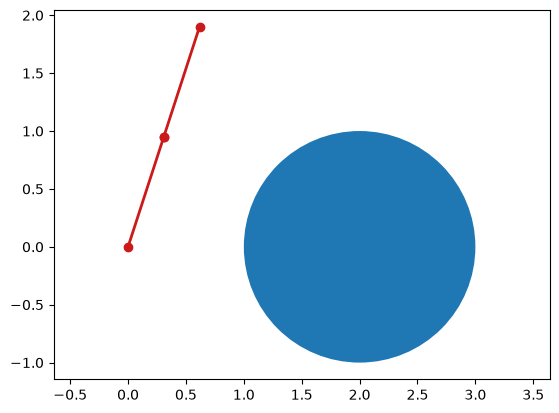

In [6]:
angles = np.array([np.pi/2.5,0]) # [angle1,angle2] in radians
joints = move_2R(angles)
obstacle = [2,0,1] # [x,y,radius]
render_2R(joints,obstacle)
print("positions of joints: ",joints)

https://en.wikipedia.org/wiki/Vector_projection

https://en.wikipedia.org/wiki/Distance_from_a_point_to_a_line

https://math.stackexchange.com/questions/1300484/distance-between-line-and-a-point

https://en.wikipedia.org/wiki/Distance_from_a_point_to_a_plane

In [7]:
def check_collision_2R(joints, obstacle):
    # Check whether any joint is inside or on the circle.
    for joint in joints:
        if check_collision(joint, obstacle):
            return True
    return False


def check_collision_2R_segment(joints, obstacle):
    center = np.array(obstacle[:2])
    radius = obstacle[2]
    for start, end in zip(joints[:-1], joints[1:]):
        link = end - start
        length_squared = np.dot(link, link)
        if length_squared == 0:
            closest_point = start
        else:
            # Project onto the link and clamp to its two endpoints.
            t = np.dot(center - start, link) / length_squared
            t = np.clip(t, 0, 1)
            closest_point = start + t * link
        if np.linalg.norm(closest_point - center) <= radius:
            return True
    return False


step  0  collision detected:  False
step  1  collision detected:  False
step  2  collision detected:  False
step  3  collision detected:  False
step  4  collision detected:  False
step  5  collision detected:  False
step  6  collision detected:  False
step  7  collision detected:  False
step  8  collision detected:  False
step  9  collision detected:  False


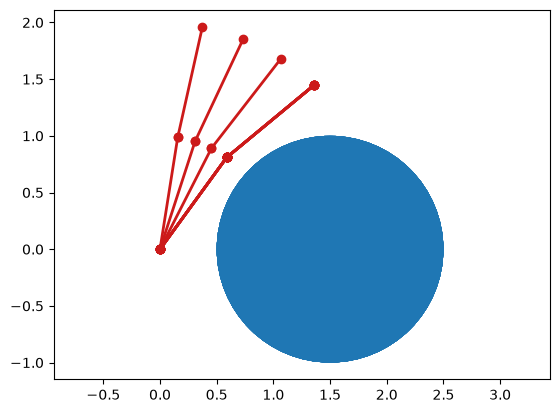

In [8]:
angles = np.array([np.pi/2, 0]) # Joint angles in radians.
obstacle = [1.5, 0, 1] # x, y, radius
velocity = np.array([-np.pi/20, -np.pi/50])
for step in range(10):
    next_angles = angles + velocity
    next_joints = move_2R(next_angles)
    if check_collision_2R_segment(next_joints, obstacle):
        velocity = np.zeros(2) # Stop before a link touches the obstacle.
    else:
        angles = next_angles
    joints = move_2R(angles)
    collision = check_collision_2R_segment(joints, obstacle)
    render_2R(joints, obstacle)
    print("step ", step, " collision detected: ", collision)


### Task 3: Difference with discrete space
* A - What would be the size of state space for 2R manipulator with 1-degree descritization?
* B - What would be the size of state space for 4R manipulator with 1-degree descritization?
* C - Can you explain the differences between discrete space and continuous space?

https://en.wikipedia.org/wiki/Discretization

https://en.wikipedia.org/wiki/Degrees_of_freedom

In [9]:
# Assume every joint can rotate through a full turn, with no joint limits.
# 0 and 360 degrees are the same angle, so each joint has 360 states.
size_of_state_space_2R = 360 ** 2
size_of_state_space_4R = 360 ** 4
print("size of state space 2R ", size_of_state_space_2R)
print("size of state space 4R ", size_of_state_space_4R)

# A discrete space uses a finite set of sampled angles; a continuous space
# allows any real-valued angle and has infinitely many configurations.
# Finer discretization improves resolution but increases the number of states
# exponentially with the number of joints. Collision checks at sampled
# configurations alone can miss collisions between them during motion.


size of state space 2R  129600
size of state space 4R  16796160000


### Task 4: Distances in manipulator scheme
* A - calculate distance between two position of manipulator

distance between two manipulator is  1.7562036827601817


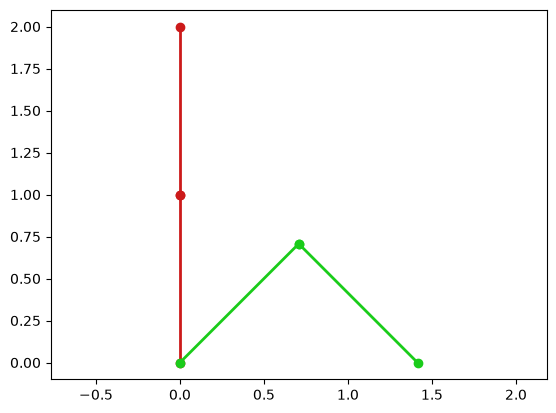

In [10]:
angles_one = np.array([np.pi/2,0]) # [angle1,angle2] in radians
angles_two = np.array([np.pi/4,-np.pi/2]) # [angle1,angle2] in radians
joints_one = move_2R(angles_one)
joints_two = move_2R(angles_two)
color_one = [0.8,0.1,0.1]
color_two = [0.1,0.8,0.1]
render_2R(joints_one, color = color_one)
render_2R(joints_two, color = color_two)
# Distance in configuration space: use the shortest angular difference
# for each joint, then take the Euclidean norm (in radians).
angle_difference = (angles_two - angles_one + np.pi) % (2 * np.pi) - np.pi
distance = np.linalg.norm(angle_difference)
print("distance between two manipulator is ", distance)